In [1]:
import pandas as pd
import numpy as np

In [54]:
df = pd.read_csv('synthetic_mof_synthesis.csv')
df.head(2)

,sample_id,mof_family,metal_salt,linker,solvent,modulator,modulator_equiv,metal_linker_ratio,concentration_M,temperature_C,time_h,batch,relative_crystallinity,phase_outcome,yield_pct,BET_m2_g
0,M0000,MIL-53(Al),Al(NO3)3,terephthalic acid,H2O,none,0,0.84,0.104,210.7,35.30,6,0.673,phase-pure MOF,80.0,609.0
1,M0001,UiO-66,ZrCl4,terephthalic acid,DMF,none,0,0.92,0.091,108.1,8.49,8,0.751,phase-pure MOF,68.2,818.0


In [55]:
df['phase_outcome'].value_counts()

phase_outcome
phase-pure MOF     357
mixed phase        233
amorphous/other     70
Name: count, dtype: int64

In [56]:
mapping = {'phase-pure MOF': 0, 'mixed phase':1, 'amorphous/other':2}

df['phase_outcome'] = df['phase_outcome'].map(mapping)
df['phase_outcome'].value_counts()


phase_outcome
0    357
1    233
2     70
Name: count, dtype: int64

In [57]:
df2 = df.drop(columns=['sample_id',	'mof_family',	'temperature_C', 'batch', 'metal_salt',	'linker',	'solvent',	'modulator', 'time_h', 'BET_m2_g', 'yield_pct', 'modulator_equiv'])
df2.head(2)

,metal_linker_ratio,concentration_M,relative_crystallinity,phase_outcome
0,0.84,0.104,0.673,0
1,0.92,0.091,0.751,0


In [58]:
df2 = df2.rename(columns = {'metal_linker_ratio': 'feature1',
                           'concentration_M': 'feature2',
                           'relative_crystallinity': 'feature3',
                           'phase_outcome': 'target'})
df2.head()

,feature1,feature2,feature3,target
0,0.84,0.104,0.673,0
1,0.92,0.091,0.751,0
2,6.90,0.065,0.157,2
3,1.27,0.159,0.701,0
4,1.75,0.063,0.428,1


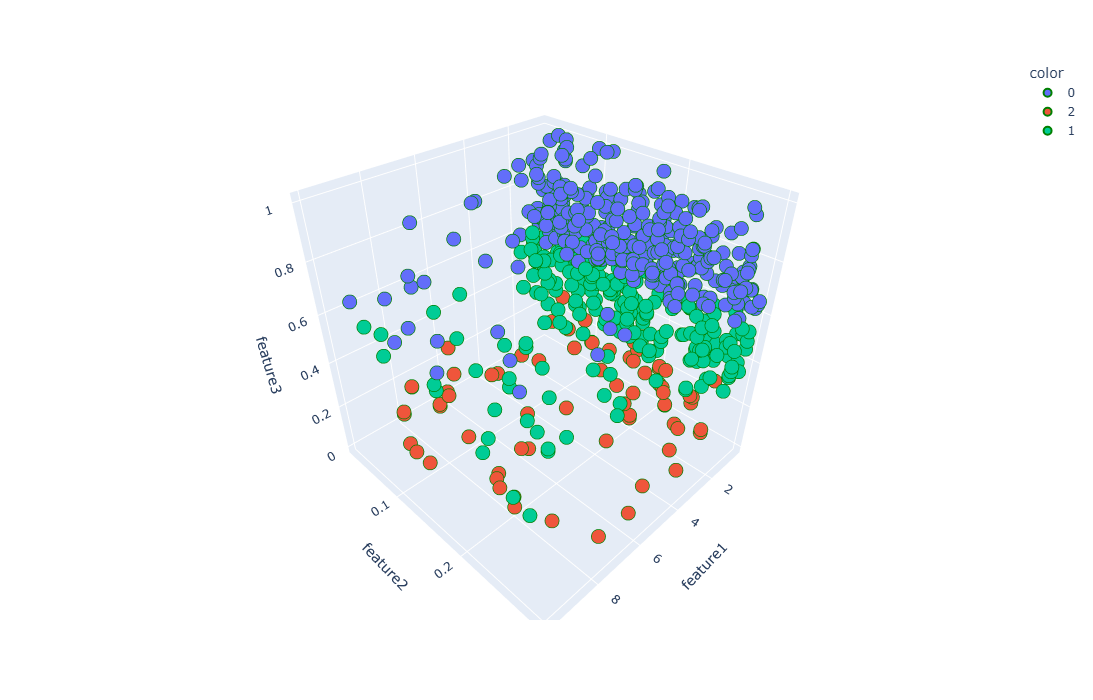

In [59]:
import plotly.express as px



fig = px.scatter_3d(df2, x=df2['feature1'], y=df2['feature2'], 
                   z=df2['feature3'], color = df2['target'].astype('str'), width=900, height=700)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color='green')),
                 selector = dict(mode='markers'))

fig.show()

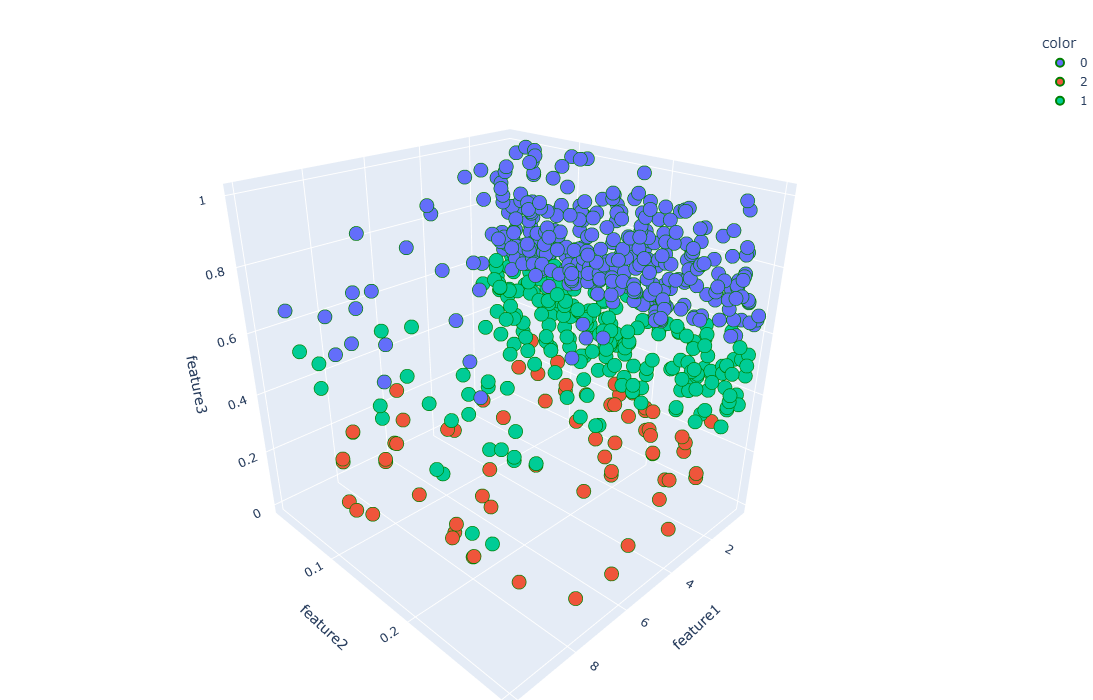

In [60]:

fig = px.scatter_3d(df2, x=df2['feature1'], y=df2['feature2'], 
                   z=df2['feature3'], color = df2['target'].astype('str'), width=900, height=700)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color='green')),
                 selector = dict(mode='markers'))

fig.update_layout(margin=dict(l=0, r=0, t=30, b=0),            # removes the white space
                  scene_camera=dict(eye=dict(x=1.4, y=1.4, z=1.0)))   # zooms in a little

fig.show()

## Step 1 - Apply standard scaling -- mean centering

In [61]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [62]:
df2.head(2)

,feature1,feature2,feature3,target
0,0.84,0.104,0.673,0
1,0.92,0.091,0.751,0


In [39]:
df2.iloc[:, 0:3] = scaler.fit_transform(df2.iloc[:, 0:3])

## Step 2 - Find Covariance

In [63]:
cov_matrix = np.cov([df2.iloc[:,0], df2.iloc[:,1], df2.iloc[:,2]])
print('cov_matrix:\n', cov_matrix)

cov_matrix:
 [[ 4.39886463e+00 -9.20056670e-03 -1.52985180e-01]
 [-9.20056670e-03  6.58286739e-03 -7.65097163e-04]
 [-1.52985180e-01 -7.65097163e-04  4.85443571e-02]]


## diagonal items are variance of all columns and the others are covariance values

## Step 3 - Find Eigen vector and Eigen value

In [64]:
eigen_values, eigen_vectors = np.linalg.eig(cov_matrix)

eigen_vectors

array([[ 0.9993816 , -0.0350236 , -0.00312398],
       [-0.00208474,  0.02966996, -0.99955758],
       [-0.0351008 , -0.99894596, -0.02957859]])

In [65]:
eigen_values

array([4.40425704, 0.04320334, 0.00653147])

In [66]:
pc = eigen_vectors[0:2]
pc

array([[ 0.9993816 , -0.0350236 , -0.00312398],
       [-0.00208474,  0.02966996, -0.99955758]])

In [67]:
transformed_df2 = np.dot(df2.iloc[:, 0:3], pc.T)    ## 650 , 5  - 3,2

new_df2  = pd.DataFrame(transformed_df2, columns=['PC1', 'PC2'])
new_df2['target'] = df2['target'].values

new_df2.head()

,PC1,PC2,target
0,0.833736,-0.671368,0
1,0.913898,-0.749886,0
2,6.892966,-0.169387,2
3,1.261456,-0.698620,0
4,1.745374,-0.429590,1


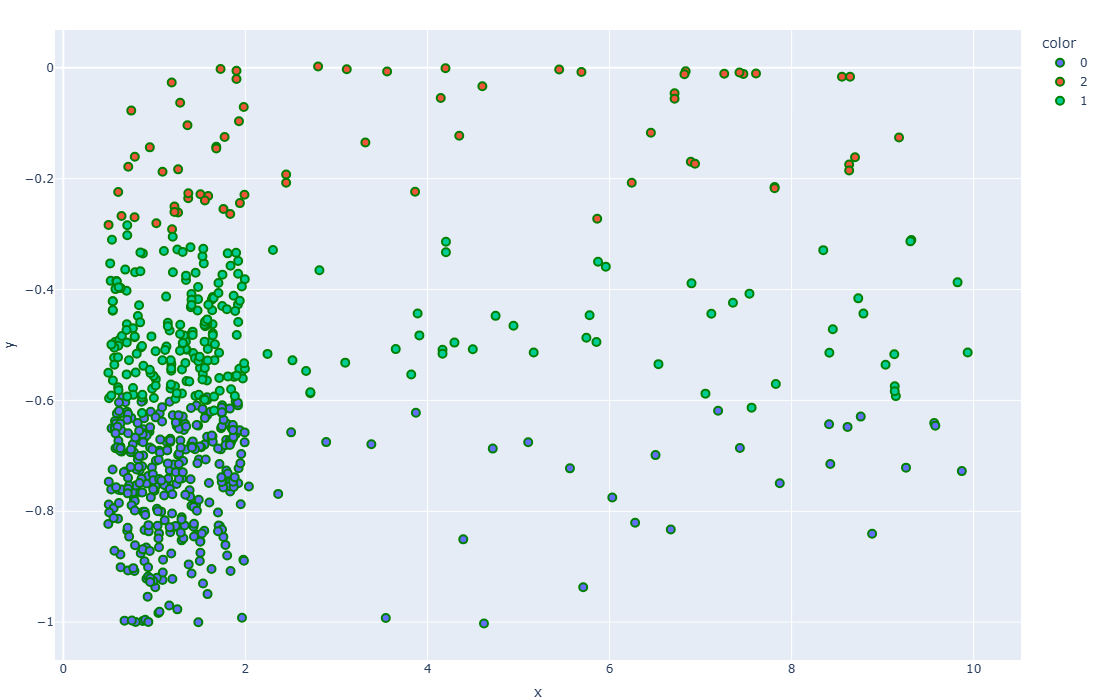

In [68]:
new_df2['target'] = new_df2['target'].astype('str')

fig = px.scatter(x=new_df2['PC1'], y=new_df2['PC2'], 
                   color = new_df2['target'], width=900, height=700)

fig.update_traces(marker = dict(size = 8, line = dict(width = 2, color='green')),
                 selector = dict(mode='markers'))

fig.update_layout(margin=dict(l=0, r=0, t=30, b=0),            # removes the white space
                  scene_camera=dict(eye=dict(x=1.4, y=1.4, z=1.0)))   # zooms in a little

fig.show()